In [1]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib import cm
from statsmodels.regression.mixed_linear_model import MixedLM

def read_mr_estimator_results(result_directory, output_directory = None):
    """made output_directory optional. But highly recommended since integration of all data may take some time

    Args:
        result_directory (str): _description_
        output_directory (_type_, optional): _description_. Defaults to None.

    Returns:
        _type_: _description_
    """
    files = [f for f in os.listdir(result_directory) if f.endswith(".parquet")]

    all_data = []
    for filename in files:
        filename_split = filename.split('_') # with filename pattern being:  "animal name _ experimental day _ task _ tetrode nr. _ brain area _ pre or post treatment _ timechunk .parquet"
        
        df = pd.read_parquet(f'{result_directory}/{filename}')
        df['tau'] = df['tau'][0]
        df['animal'] = filename_split[0]
        df['area'] = filename_split [3]
        df['task'] = filename_split[2]
        df['day'] = int(filename_split[1][1:])
        df['treatment'] = filename_split[4]
        df['snippet'] = filename_split[5].split('.')[0]
        all_data.append(df)

    # Combine all data
    df = pd.concat(all_data, ignore_index=True)

    # Convert categorical variables
    df['area'] = df['area'].astype('category')
    df['animal'] = df['animal'].astype('category')
    df['task'] = df['task'].astype('category')
    df['treatment'] = df['treatment'].astype('category')

    if output_directory:
        df.to_parquet(f'{output_directory}big_df.parquet')
    
    return df

def clean_df(df):
    df = df[df['tau'] <= 3000]

    selected_areas = ["CA1", "CA2", "CA3"]  # Replace with your desired values
    df = df[df["area"].isin(selected_areas)]

    df['area'] = df['area'].astype('category')
    df['area'] = df['area'].cat.remove_unused_categories()
    
    df['state'] = df['task'].apply(lambda x: 'run' if str(x).startswith('lt') else 'sleep')
    
    return df

def interaction_plot(df, measure):
    plt.figure(figsize=(8,6))

    # Plot mean ± SEM for each area, grouped by state
    sns.pointplot(data=df, x="area", y=measure, hue="state", dodge=True, capsize=0.1, markers="o", errwidth=1, palette="viridis")

    plt.xlabel("Brain Area")
    plt.ylabel(f"Mean {measure} ± SEM")
    plt.title("Interaction Plot: State × Brain Area")
    plt.legend(title="State")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()

def grouped_violin_plot(df, measure, smooth = 0.1):
    # Set figure size
    plt.figure(figsize=(8, 6))

    # Create a violin plot
    sns.violinplot(data=df, x="area", y=measure, hue="state", split=True, inner= "box", bw_method=smooth, palette="viridis")

    # Labels and title
    plt.xlabel("Brain Area")
    plt.ylabel(f"{measure} Value")
    plt.title(f"Grouped Violin Plots: {measure} by Brain Area & State")

    # Adjust legend
    plt.legend(title="State")

    # Show grid for readability
    plt.grid(True, linestyle="--", alpha=0.5)

    # Display plot
    plt.show()

def violin_interaction_plot(df, measure, smooth = 0.1):
    # Set figure size
    plt.figure(figsize=(10, 6))

    # Create a new categorical x-axis combining 'area' and 'state'
    df["group"] = df["area"].astype(str) + "-" + df["state"].astype(str)


    # Sort so CA1-run, CA1-sleep, etc., are in the correct order
    df["group"] = pd.Categorical(df["group"], categories=[
        "CA1-run", "CA1-sleep", "CA2-run", "CA2-sleep", "CA3-run", "CA3-sleep"
    ], ordered=True)

    # Create violin plot
    sns.violinplot(data=df, x="group", y= measure, inner="quartile", color="lightgray", bw_method=smooth)

    # Compute means and standard errors
    means = df.groupby("group")[measure].mean()
    sems = df.groupby("group")[measure].sem()

    # Overlay mean points with error bars
    plt.errorbar(x=range(len(means)), y=means, yerr=sems, fmt="o", color="black", capsize=5, label="Mean ± SEM")

    # Extract x-coordinates for connecting lines
    run_indices = [0, 2, 4]  # CA1-run, CA2-run, CA3-run
    sleep_indices = [1, 3, 5]  # CA1-sleep, CA2-sleep, CA3-sleep

    plt.plot(run_indices, means.iloc[run_indices], marker="o", linestyle="-", color= cm.viridis(0.3), label="Run")
    plt.plot(sleep_indices, means.iloc[sleep_indices], marker="o", linestyle="-", color= cm.viridis(0.7), label="Sleep")

    # Labels & legend
    plt.xlabel("Brain Area & State")
    plt.ylabel("Tau Value")
    plt.title(f"{measure}: Violin Plot with Mean ± SEM and Interaction Lines")
    plt.xticks(rotation=45)
    plt.legend()
    
    plt.grid(axis="y", linestyle="-", linewidth=0.5, alpha=0.3)
    plt.gca().set_axisbelow(True)
    
    # Show plot
    plt.show()

def density_plot(df, measure, log = False):
    # Set figure size
    plt.figure(figsize=(12, 5))

    # Create separate plots for each state
    states = df["state"].unique()
    for i, state in enumerate(states, 1):
        plt.subplot(1, len(states), i)  # One subplot per state
        
        # Filter data for the current state
        subset = df[df["state"] == state]
        
        # Plot density for each brain area
        sns.kdeplot(data=subset, x=measure, hue="area", common_norm=False, bw_adjust=0.8, fill=True, alpha=0.05, palette="viridis")
        
        # Titles and labels
        plt.title(f"{measure}: Density Plot - {state.capitalize()}")
        plt.xlabel(measure)
        plt.ylabel("Density")
        
        if log:
            plt.xscale("log")
            plt.yscale("log")
            plt.grid(True, which="both", linestyle="--", linewidth=0.5)

    plt.tight_layout()
    plt.show()


In [2]:
df_control = read_mr_estimator_results('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_CTRL/results/')
df_control.to_parquet('/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/models_and_figures/big_df_control.parquet')

Put all results into one dataframe

In [2]:
df = pd.read_parquet("/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/models_and_figures/big_df.parquet")
df_control = pd.read_parquet("/groups/cns/share/Vincent/McHugh_lab/CA2Cre_DREADD/models_and_figures/big_df_control.parquet")

df['dataset'] = 'MH_dreadd'
df_control['dataset'] = 'MH_ctrl'
df = pd.concat([df, df_control], ignore_index=True)

In [ ]:
# Filter df to rows where task is one of lt11, lt12, lt13
lt_tasks = ['lt11', 'lt12', 'lt13']
df_lt = df[df['task'].isin(lt_tasks)]

# Group by animal and day, and check if both 'pre' and 'post' treatments exist
valid_animal_day = df_lt.groupby(['animal', 'day'])['treatment'].apply(lambda x: set(x) == {'pre', 'post'}).reset_index()
valid_animal_day = valid_animal_day[valid_animal_day['treatment'] == True][['animal', 'day']]

# Merge back to get the filtered df
df_filtered = df.merge(valid_animal_day, on=['animal', 'day'])

,popt,ssres,steps,dt,dtunit,quantiles,mrequantiles,tauquantiles,description,tau,...,activity,animal,day,task,area,treatment,timechunk,distance_criticality,dataset,snippet
0,"[78.42746413057257, 0.03415812917882224, -1.54...",0.115052,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,ms,None,None,None,None,78.427464,...,2280,model572,d17,sleep3,CA1,post,5.0,-4.368543,MH_dreadd,NaN
1,"[120.31255356110354, 0.0348522019718514, -0.00...",0.121734,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,ms,None,None,None,None,120.312554,...,1018,model368,d16,cno1,CA3,post,16.0,-4.794246,MH_dreadd,NaN
2,"[1009.2635184400931, 0.023504045289931, -0.009...",0.115746,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,ms,None,None,None,None,1009.263518,...,3455,model368,d13,sleep3,CA3,pre,0.0,-6.917472,MH_dreadd,NaN
3,"[182.82912223761508, 0.03460506804339023, 0.00...",0.106366,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,ms,None,None,None,None,182.829122,...,38295,model1216,d12,cno?,CA2,post,18.0,-5.211286,MH_dreadd,NaN
4,"[13.754500262654838, 0.1240744768629935, -9.63...",0.101305,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...",1,ms,None,None,None,None,13.754500,...,1433,model1223,d15,lt12,CA2,post,3.0,-2.657498,MH_dreadd,NaN


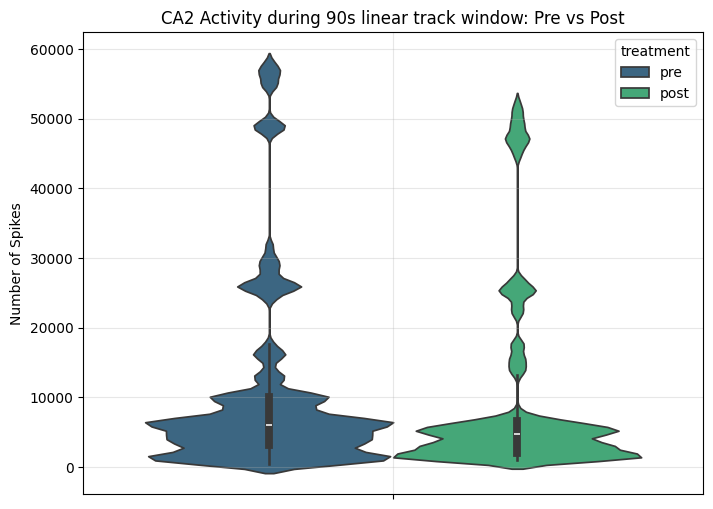

In [23]:
ca2_lt_df = df[(df['area'] == 'CA2') & (df['task'].str.startswith('lt'))]
plt.figure(figsize=(8, 6))
sns.violinplot(data=ca2_lt_df, hue='treatment', y='activity', palette='viridis', bw_method=.05, hue_order=['pre', 'post'])
plt.title('CA2 Activity during 90s linear track window: Pre vs Post')
plt.ylabel('Number of Spikes')
plt.grid(True, alpha=0.3)
plt.show()

filter data

In [9]:
df = clean_df(df)
df = df[df['treatment'] == 'pre']
df_control = clean_df(df_control)
#df_joined_mchugh = 

In [19]:
print(df_control.columns)

Index(['popt', 'ssres', 'steps', 'dt', 'dtunit', 'quantiles', 'mrequantiles',
       'tauquantiles', 'description', 'tau', 'branching_factor', 'num_neurons',
       'activity', 'animal', 'area', 'state', 'day', 'epoch', 'timestamp',
       'arm'],
      dtype='object')


In [10]:
df['state'] = df['task'].apply(lambda x: 'run' if str(x).startswith('lt') else 'rest')

/tmp/ipykernel_990707/2169193494.py:66: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.pointplot(data=df, x="area", y=measure, hue="state", dodge=True, capsize=0.1, markers="o", errwidth=1, palette="viridis")


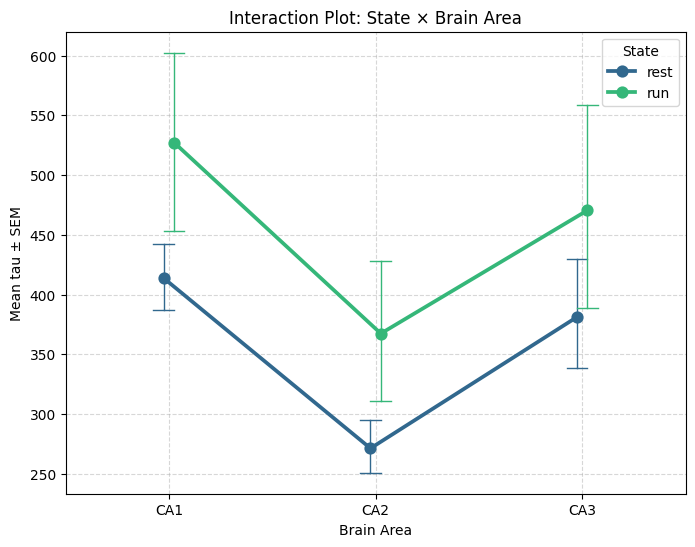

/tmp/ipykernel_990707/2169193494.py:66: FutureWarning: 

The `errwidth` parameter is deprecated. And will be removed in v0.15.0. Pass `err_kws={'linewidth': 1}` instead.

  sns.pointplot(data=df, x="area", y=measure, hue="state", dodge=True, capsize=0.1, markers="o", errwidth=1, palette="viridis")


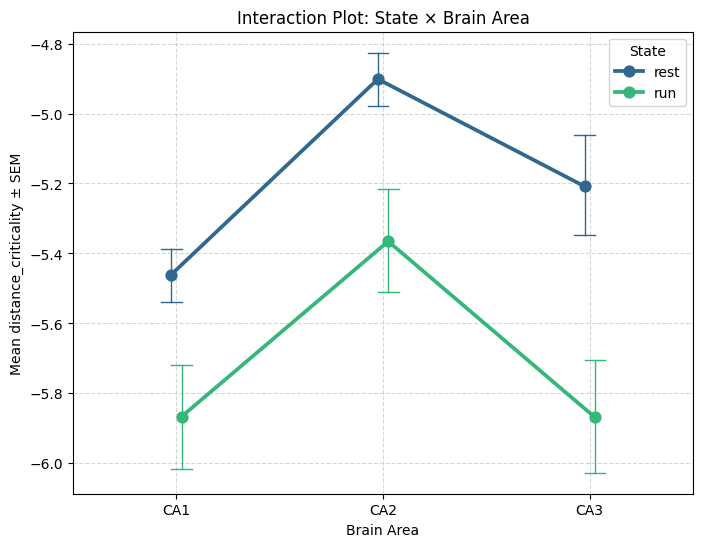

In [11]:
interaction_plot(df, 'tau')
interaction_plot(df, 'distance_criticality')

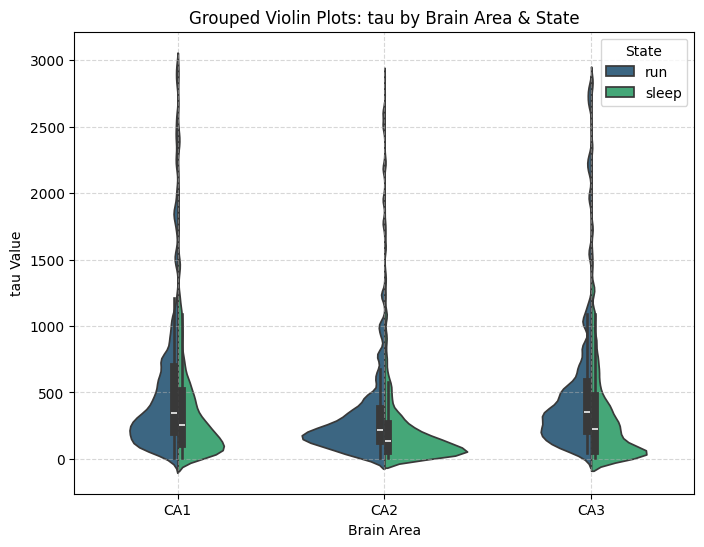

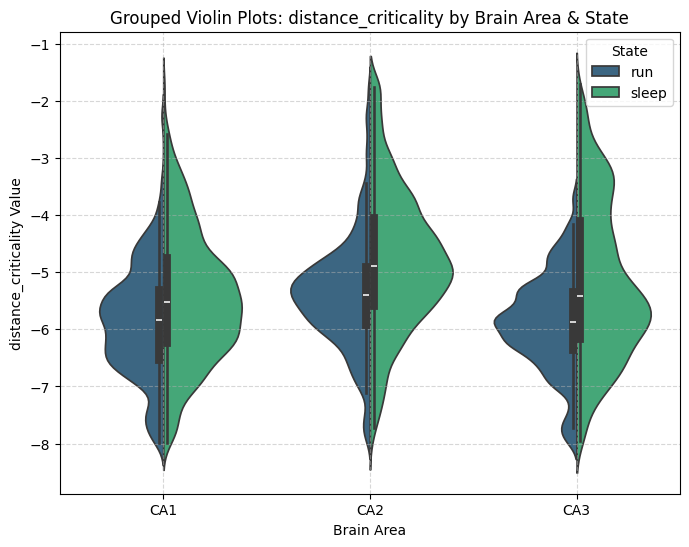

In [33]:
grouped_violin_plot(df, 'tau')
grouped_violin_plot(df, 'distance_criticality', smooth=0.2)

/tmp/ipykernel_67733/1281310033.py:98: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = df.groupby("group")[measure].mean()
/tmp/ipykernel_67733/1281310033.py:99: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sems = df.groupby("group")[measure].sem()


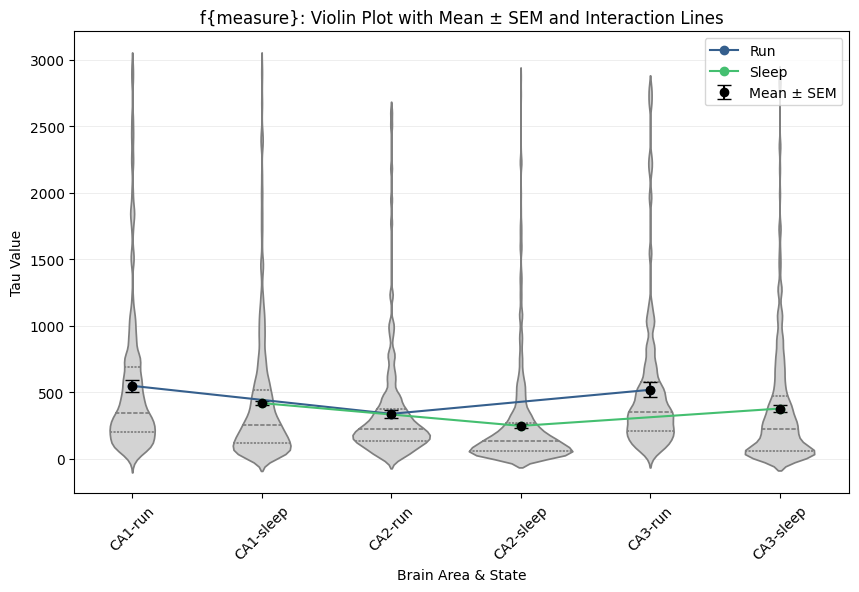

/tmp/ipykernel_67733/1281310033.py:98: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = df.groupby("group")[measure].mean()
/tmp/ipykernel_67733/1281310033.py:99: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sems = df.groupby("group")[measure].sem()


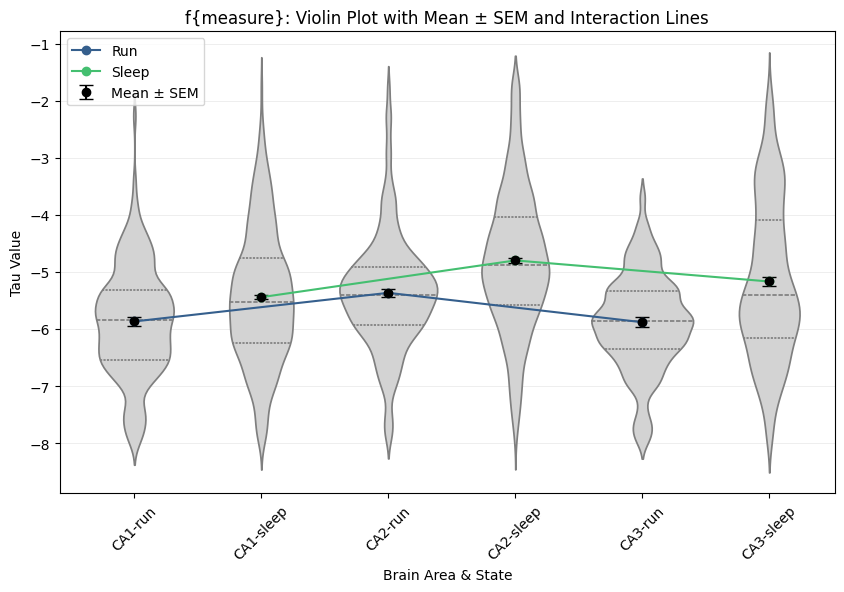

/tmp/ipykernel_67733/1281310033.py:98: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  means = df.groupby("group")[measure].mean()
/tmp/ipykernel_67733/1281310033.py:99: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  sems = df.groupby("group")[measure].sem()


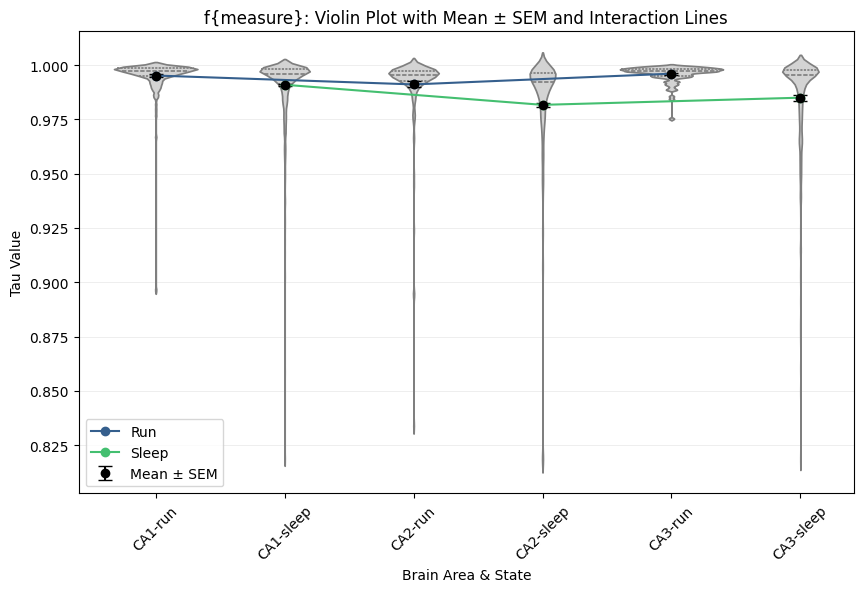

In [34]:
violin_interaction_plot(df, 'tau')
violin_interaction_plot(df, 'distance_criticality', smooth=0.2)
violin_interaction_plot(df, 'branching_factor')

Compare data from McHugh and Loren Frank

In [5]:
df_lf = pd.read_parquet('/groups/cns/dekorvyb/general_analysis/big_df.parquet') 

areas_oi = {'CA1', 'CA2', 'CA3'}
df_lf = df_lf[df_lf['area'].isin(areas_oi)]
df_lf['area'] = df_lf['area'].cat.remove_unused_categories()

df_lf = df_lf[df_lf['tau'] <= 3000]

Create combined df only for run sessions of loren frank and McHugh dataset

In [6]:
# Add 'dataset' column to each dataframe
df['dataset'] = 'MH'
df_lf['dataset'] = 'LF'

# Concatenate the two dataframes
df_combined = pd.concat([df, df_lf], ignore_index=True)
df_combined_run = df_combined[df_combined['state'] == 'run']


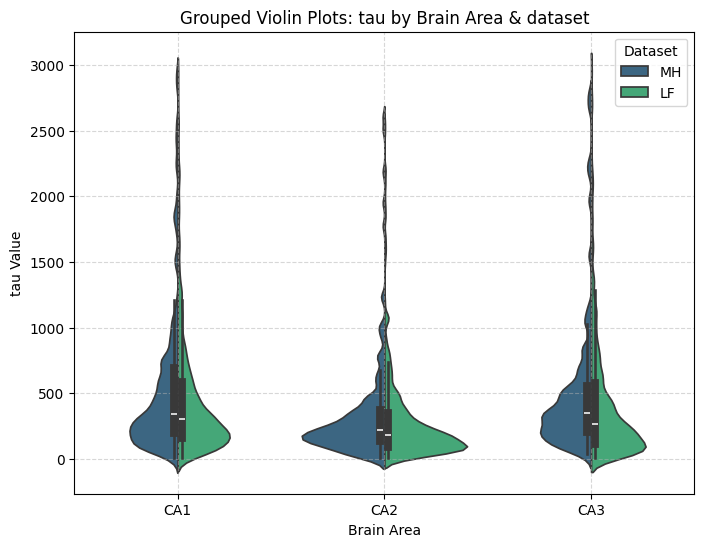

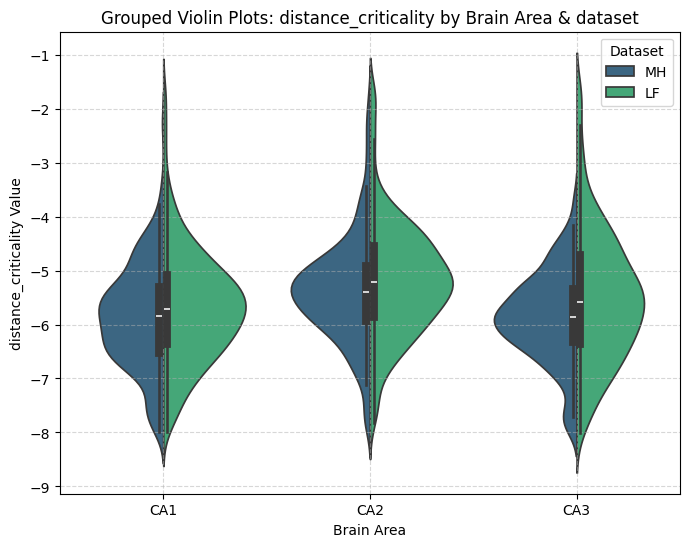

In [37]:
def grouped_violin_plot_combined_datasets(df, measure, smooth = 0.1):
    # Set figure size
    plt.figure(figsize=(8, 6))

    # Create a violin plot
    sns.violinplot(data=df, x="area", y=measure, hue="dataset", split=True, inner= "box", bw_method=smooth, palette="viridis")

    # Labels and title
    plt.xlabel("Brain Area")
    plt.ylabel(f"{measure} Value")
    plt.title(f"Grouped Violin Plots: {measure} by Brain Area & dataset")

    # Adjust legend
    plt.legend(title="Dataset")

    # Show grid for readability
    plt.grid(True, linestyle="--", alpha=0.5)

    # Display plot
    plt.show()

grouped_violin_plot_combined_datasets(df_combined_run, 'tau')
grouped_violin_plot_combined_datasets(df_combined_run, 'distance_criticality', smooth = 0.3)

Create a statistical model to compare the distance to criticality between both datasets
    --> almost everything is statistical significant, but it might be because of the model.


In [9]:
model = MixedLM.from_formula("distance_criticality ~ dataset*C(state, Treatment(reference='sleep')) + dataset*C(area, Treatment(reference='CA1'))", 
                             groups="animal", 
                             data=df_combined)

result = model.fit()

# Summarize Results
print(result.summary())

                                 Mixed Linear Model Regression Results
Model:                         MixedLM             Dependent Variable:             distance_criticality
No. Observations:              12869               Method:                         REML                
No. Groups:                    21                  Scale:                          1.7812              
Min. group size:               153                 Log-Likelihood:                 -22011.6258         
Max. group size:               1647                Converged:                      Yes                 
Mean group size:               612.8                                                                   
-------------------------------------------------------------------------------------------------------
                                                            Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-------------------------------------------------------------------------------------------------

Statistical Model: distance to criticality

In [ ]:
model = MixedLM.from_formula("distance_criticality ~ C(state, Treatment(reference='sleep')) * C(area, Treatment(reference='CA1'))", 
                             groups="animal", 
                             data=df)

result = model.fit()

# Summarize Results
print(result.summary())

                                               Mixed Linear Model Regression Results
Model:                                  MixedLM                       Dependent Variable:                       distance_criticality
No. Observations:                       2519                          Method:                                   REML                
No. Groups:                             10                            Scale:                                    1.3926              
Min. group size:                        136                           Log-Likelihood:                           -4005.7870          
Max. group size:                        497                           Converged:                                Yes                 
Mean group size:                        251.9                                                                                       
---------------------------------------------------------------------------------------------------------------------

Statistical model: tau

In [7]:
model = MixedLM.from_formula("tau ~ C(state, Treatment(reference='sleep')) * C(area, Treatment(reference='CA1'))", 
                             groups="animal", 
                             data=df)

result = model.fit()

# Summarize Results
print(result.summary())

/home/dekorvyb/miniconda3/envs/criticality_env/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/dekorvyb/miniconda3/envs/criticality_env/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


                                                  Mixed Linear Model Regression Results
Model:                                        MixedLM                           Dependent Variable:                           tau        
No. Observations:                             2519                              Method:                                       REML       
No. Groups:                                   10                                Scale:                                        200570.2503
Min. group size:                              136                               Log-Likelihood:                               -18928.1281
Max. group size:                              497                               Converged:                                    No         
Mean group size:                              251.9                                                                                      
------------------------------------------------------------------------------------

/home/dekorvyb/miniconda3/envs/criticality_env/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/dekorvyb/miniconda3/envs/criticality_env/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
/home/dekorvyb/miniconda3/envs/criticality_env/lib/python3.13/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/dekorvyb/miniconda3/envs/criticality_env/lib/python3.13/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/home/dekorvyb/miniconda3/